<h1 style="text-align:center;">Final Project: Evaluating the Drivers of Basketball Player Performance</h1>


## Executive Summary

This project examines whether physical attributes, especially height and weight, meaningfully explain basketball player performance and career longevity. The analysis combines a player-level dataset, a season-level performance dataset, and supplemental player information collected through an API.

The main finding is that physical size alone does not strongly predict scoring performance. Height is more clearly related to rebounding, while scoring appears more connected to position, role, and skill-based factors. This suggests that player success is multi-dimensional rather than purely determined by physical traits.

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)

players = pd.read_csv("player_data.csv")
stats = pd.read_csv("Seasons_Stats.csv")

players["name"] = players["name"].str.strip()
stats["Player"] = stats["Player"].str.strip()

players.head()

,name,year_start,year_end,position,height,weight,birth_date,college
0,Alaa Abdelnaby,1991,1995,F-C,6-10,240.0,"June 24, 1968",Duke University
1,Zaid Abdul-Aziz,1969,1978,C-F,6-9,235.0,"April 7, 1946",Iowa State University
2,Kareem Abdul-Jabbar,1970,1989,C,7-2,225.0,"April 16, 1947","University of California, Los Angeles"
3,Mahmoud Abdul-Rauf,1991,2001,G,6-1,162.0,"March 9, 1969",Louisiana State University
4,Tariq Abdul-Wahad,1998,2003,F,6-6,223.0,"November 3, 1974",San Jose State University


## Data Preparation

The player dataset includes information such as name, height, weight, position, and career years. The season statistics dataset includes performance variables such as points, assists, and rebounds. Since the performance data is recorded by season, I aggregate it to the player level before merging it with the player dataset.

In [35]:
def height_to_inches(h):
    try:
        feet, inches = str(h).split("-")
        return int(feet) * 12 + int(inches)
    except:
        return None

players["height_inches"] = players["height"].apply(height_to_inches)

def simplify_position(pos):
    pos = str(pos)
    if "G" in pos:
        return "Guard"
    elif "F" in pos:
        return "Forward"
    elif "C" in pos:
        return "Center"
    else:
        return "Other"

players["pos_simple"] = players["position"].apply(simplify_position)

players[["name", "position", "pos_simple", "height", "height_inches"]].head()

,name,position,pos_simple,height,height_inches
0,Alaa Abdelnaby,F-C,Forward,6-10,82.0
1,Zaid Abdul-Aziz,C-F,Forward,6-9,81.0
2,Kareem Abdul-Jabbar,C,Center,7-2,86.0
3,Mahmoud Abdul-Rauf,G,Guard,6-1,73.0
4,Tariq Abdul-Wahad,F,Forward,6-6,78.0


In [36]:
player_stats = stats.groupby("Player").agg({
    "PTS": "mean",
    "AST": "mean",
    "TRB": "mean",
    "Year": ["min", "max"]
}).reset_index()

player_stats.columns = [
    "name",
    "avg_pts",
    "avg_ast",
    "avg_reb",
    "start_year",
    "end_year"
]

player_stats["career_length"] = player_stats["end_year"] - player_stats["start_year"]

merged = pd.merge(players, player_stats, on="name", how="inner")

merged.head()

,name,year_start,year_end,position,height,weight,birth_date,college,height_inches,pos_simple,avg_pts,avg_ast,avg_reb,start_year,end_year,career_length
0,Alaa Abdelnaby,1991,1995,F-C,6-10,240.0,"June 24, 1968",Duke University,82.0,Forward,255.444444,13.888889,144.111111,1991.0,1995.0,4.0
1,Zaid Abdul-Aziz,1969,1978,C-F,6-9,235.0,"April 7, 1946",Iowa State University,81.0,Forward,355.571429,46.285714,323.142857,1969.0,1978.0,9.0
2,Mahmoud Abdul-Rauf,1991,2001,G,6-1,162.0,"March 9, 1969",Louisiana State University,73.0,Guard,950.333333,231.000000,120.777778,1991.0,2001.0,10.0
3,Tariq Abdul-Wahad,1998,2003,F,6-6,223.0,"November 3, 1974",San Jose State University,78.0,Forward,266.200000,38.800000,115.100000,1998.0,2003.0,5.0
4,Shareef Abdur-Rahim,1997,2008,F,6-9,225.0,"December 11, 1976",University of California,81.0,Forward,1172.285714,163.071429,491.285714,1997.0,2008.0,11.0


## Data Expansion Through API

To expand the original dataset, I use TheSportsDB API to collect additional player-level information. The API returns structured JSON data when given a player name. The response can include variables such as player name, team, position, nationality, height, weight, and birth date.

The function below works by sending a request for each player name, reading the JSON response, and extracting selected player attributes into a list of dictionaries. It has two customization parameters. The first, `player_names`, changes which players are requested from the API. The second, `born_after_year`, filters the results by birth year. The output is converted into a Pandas DataFrame and saved as a CSV file for submission.

This API dataset provides additional contextual information about players and satisfies the requirement of incorporating externally collected data.

In [37]:
def get_player_api_data(player_names, born_after_year=1950):
    api_data = []
    
    for name in player_names:
        search_name = name.replace(" ", "_")
        url = f"https://www.thesportsdb.com/api/v1/json/3/searchplayers.php?p={search_name}"
        
        response = requests.get(url)
        data = response.json()
        
        if data.get("player") is not None:
            player = data["player"][0]
            
            birth_year = None
            if player.get("dateBorn"):
                birth_year = int(player["dateBorn"][:4])
            
            if birth_year is None or birth_year >= born_after_year:
                api_data.append({
                    "name": player.get("strPlayer"),
                    "api_team": player.get("strTeam"),
                    "api_position": player.get("strPosition"),
                    "api_nationality": player.get("strNationality"),
                    "api_height": player.get("strHeight"),
                    "api_weight": player.get("strWeight"),
                    "api_birth_date": player.get("dateBorn")
                })
    
    return pd.DataFrame(api_data)

In [38]:
player_list = [
    "Michael Jordan",
    "LeBron James",
    "Kobe Bryant",
    "Shaquille O'Neal",
    "Stephen Curry",
    "Tim Duncan",
    "Kevin Durant",
    "Magic Johnson",
    "Larry Bird",
    "Kareem Abdul-Jabbar"
]

api_players = get_player_api_data(player_list, born_after_year=1950)

api_players.to_csv("api_players.csv", index=False)

api_players

,name,api_team,api_position,api_nationality,api_height,api_weight,api_birth_date
0,Michael Jordan,_Retired Basketball,Shooting Guard,United States,None,None,1963-02-17
1,LeBron James,Los Angeles Lakers,Small Forward,United States,None,None,1984-12-30
2,Kobe Bryant,_Deceased Basketball,Shooting Guard,United States,None,None,1978-08-23
3,Shaquille O'Neal,_Retired Basketball,Center,United States,None,None,1972-03-06
4,Stephen Curry,Golden State Warriors,Point Guard,United States,None,None,1988-03-14
5,Tim Duncan,_Retired Basketball,Power Forward,United States,None,None,1976-04-25
6,Kevin Durant,Houston Rockets,Small Forward,United States,None,None,1988-09-29
7,Magic Johnson,_Retired Basketball,Point Guard,United States,None,None,1959-08-14
8,Larry Bird,_Retired Basketball,Small Forward,United States,None,None,1956-12-07


## Tidy Data

The API data is tidy because each row represents one player and each column represents one variable, such as team, position, nationality, height, weight, and birth date. This makes the dataset easy to save, inspect, and compare with the original player data.

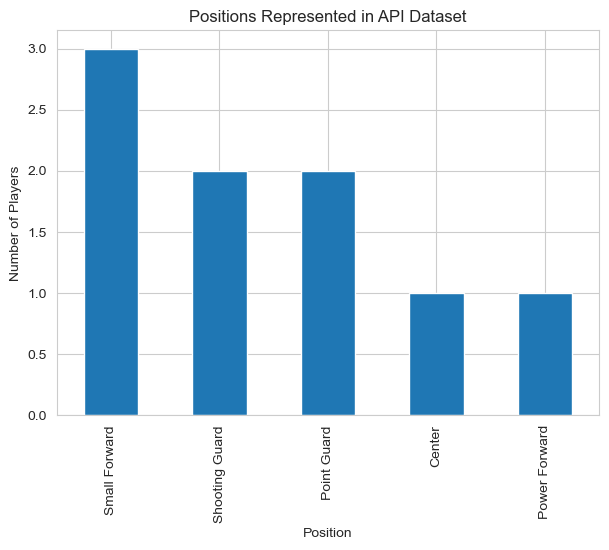

In [45]:
api_players["api_position"].value_counts().plot(kind="bar")

plt.title("Positions Represented in API Dataset")
plt.xlabel("Position")
plt.ylabel("Number of Players")
plt.show()

## Visual Analysis

The visual analysis focuses on whether performance is better explained by player role or by physical size.

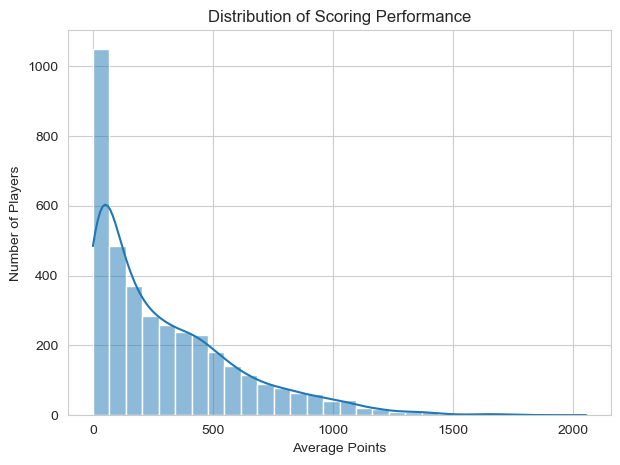

In [40]:
plt.figure(figsize=(7,5))
sns.histplot(merged["avg_pts"].dropna(), bins=30, kde=True)
plt.title("Distribution of Scoring Performance")
plt.xlabel("Average Points")
plt.ylabel("Number of Players")
plt.show()

The distribution of scoring is right-skewed, indicating that most players have moderate scoring output while a smaller group of players achieve significantly higher performance.

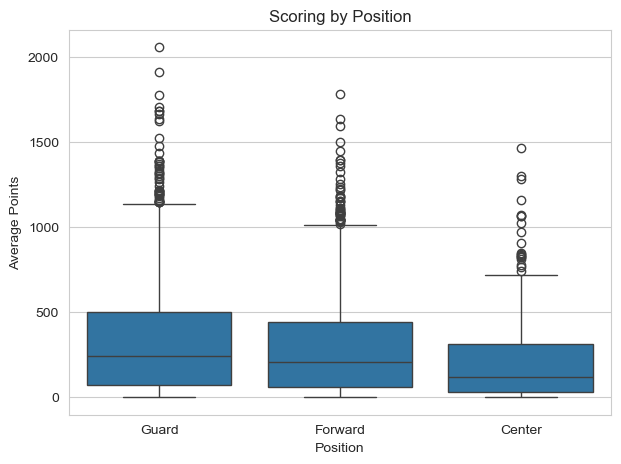

In [41]:
plt.figure(figsize=(7,5))
sns.boxplot(
    data=merged,
    x="pos_simple",
    y="avg_pts",
    order=["Guard", "Forward", "Center"]
)
plt.title("Scoring by Position")
plt.xlabel("Position")
plt.ylabel("Average Points")
plt.show()

Scoring varies by position, with guards and forwards generally showing higher scoring levels than centers, reflecting differences in offensive roles.

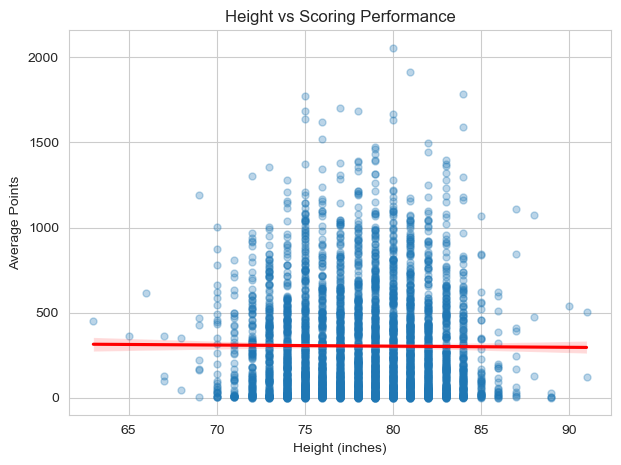

In [42]:
plt.figure(figsize=(7,5))
sns.regplot(
    data=merged,
    x="height_inches",
    y="avg_pts",
    scatter_kws={"alpha": 0.3, "s": 25},
    line_kws={"color": "red"}
)
plt.title("Height vs Scoring Performance")
plt.xlabel("Height (inches)")
plt.ylabel("Average Points")
plt.show()

The relationship between height and scoring is weak. The trend line is relatively flat, suggesting that taller players are not automatically better scorers.

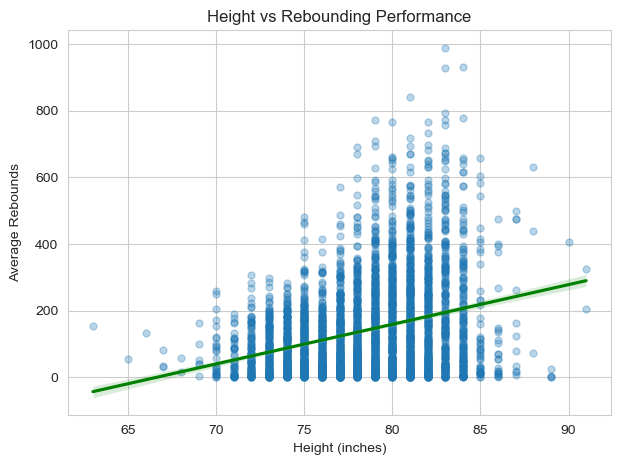

In [43]:
plt.figure(figsize=(7,5))
sns.regplot(
    data=merged,
    x="height_inches",
    y="avg_reb",
    scatter_kws={"alpha": 0.3, "s": 25},
    line_kws={"color": "green"}
)
plt.title("Height vs Rebounding Performance")
plt.xlabel("Height (inches)")
plt.ylabel("Average Rebounds")
plt.show()

Height has a clearer positive relationship with rebounding than with scoring. This suggests that physical size matters more for some performance outcomes than others.

## Conclusion

Overall, the analysis shows that physical attributes matter, but their impact depends on the performance measure. Height is not a strong predictor of scoring, but it is more relevant for rebounding. Position also matters because different positions have different responsibilities on the court.

The API data expands the project by adding supplemental player-level information, while the merged player and season datasets provide the main basis for analyzing performance. Future research could improve the analysis by using larger API samples or adding advanced statistics such as player efficiency rating or usage rate.

These findings highlight that basketball performance is multi-dimensional and cannot be explained by physical attributes alone. Future work could expand the API dataset or incorporate advanced performance metrics for deeper analysis.

## Next Steps and Hypothesis

Based on the results, one possible hypothesis is that player performance is more strongly influenced by role and skill than by physical size alone. While height appears to matter for rebounding, it does not strongly explain scoring performance.

A natural next step would be to incorporate additional performance metrics, such as shooting efficiency or player usage rate, to better understand what drives offensive success. It would also be useful to expand the API dataset to include a larger number of players, allowing for more comprehensive comparisons.

Another direction would be to analyze team context, since player performance may depend not only on individual attributes but also on team strategy and playing style. Overall, further analysis could provide a more complete understanding of the factors that contribute to player success.